# EcoFOCIpy RCM vs ADCP

Compare data using the ERDDAP hosted datasets for both instruments:
- 2D EIN/Vel datasets for the ADCP
- 1D dataset (at a specific depth) embedded in the mooring dataset


In [2]:
import pandas as pd
import xarray as xr
import numpy as np
import datetime
import EcoFOCIpy.io.erddap as erddap

url = "http://akutan.pmel.noaa.gov:8080/erddap"

erddap.test_erddap_connection(url=url) #basic test for connection to internal server, no response is a good thing

In [3]:
rcm_data = erddap.erddapMooredInstretrieve(url=url,mooringid='25ckp2a',qclevel='final',instrid='25ckp2a_rcmsg_0038m')
rcm_data.columns = [x.split()[0] for x in rcm_data.columns]

In [4]:
rcm_data = rcm_data.set_index(pd.to_datetime(rcm_data['time'])).tz_localize(None).drop('time',axis=1)

In [6]:
# adcp_data = xr.load_dataset(url+'/griddap/ADCP_Mooring_25bsp8a_final')
adcp_data = xr.load_dataset('/Users/bell/ecoraid/2025/Moorings/25ckp2a/final_data_cf/25ckp2a_wcp_velein.nc')


In [7]:
adcp_rcm_depth = adcp_data.sel(depth=(rcm_data['depth'].median()), method="nearest").to_dataframe().droplevel(['latitude','longitude'])

In [8]:
adcp_rcm_depth

,u_curr_comp,v_curr_comp,w_curr_comp,w_curr_comp_err,agc1,agc2,agc3,agc4,depth
time,,,,,,,,,
2025-08-21 06:00:00,11.347603,0.530955,0.2,0.4,140.0,148.0,142.0,141.0,29.0
2025-08-21 07:00:00,9.720586,1.232964,-0.2,0.5,137.0,145.0,139.0,138.0,29.0
2025-08-21 08:00:00,9.902071,2.721945,-0.4,0.1,136.0,145.0,139.0,138.0,29.0
2025-08-21 09:00:00,11.335236,4.562064,-1.4,-0.6,139.0,147.0,141.0,140.0,29.0
2025-08-21 10:00:00,14.371218,5.501643,0.3,-0.2,137.0,145.0,138.0,139.0,29.0
...,...,...,...,...,...,...,...,...,...
2026-09-10 13:00:00,14.490003,3.170144,0.0,-0.6,126.0,137.0,128.0,129.0,29.0
2026-09-10 14:00:00,15.957259,1.983906,0.1,-0.4,127.0,137.0,130.0,130.0,29.0
2026-09-10 15:00:00,16.465685,2.022677,0.1,0.1,127.0,136.0,131.0,129.0,29.0


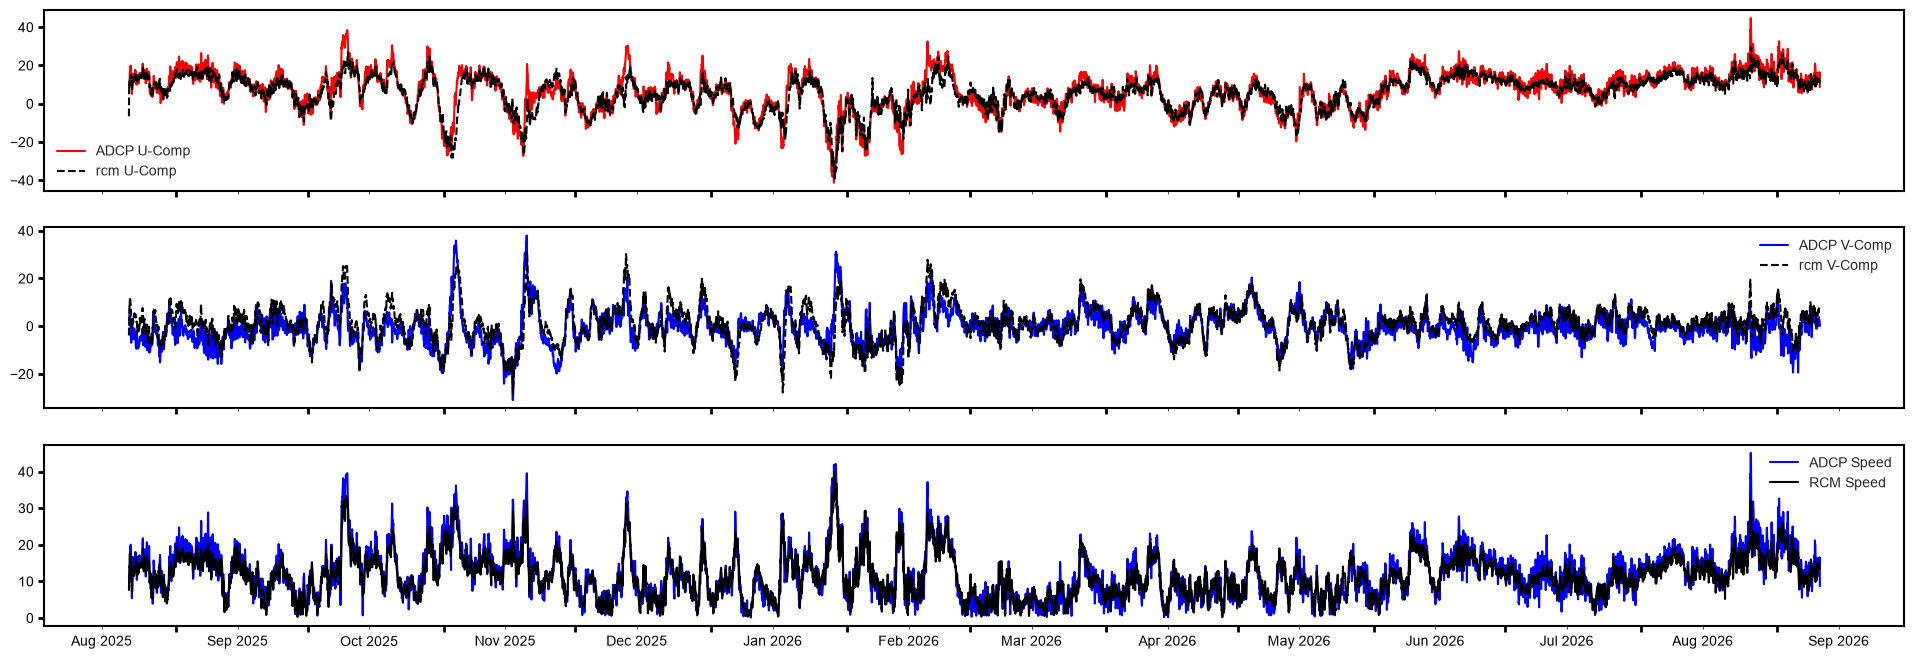

In [9]:
#wrap the plot in image settings for visual appeal
# may be able to make this cleaner or just a preset
# copy is in the notebook examples
%run '../../../settings/mpl_plot_settings.py'

%matplotlib inline
import matplotlib.dates as mdates
from matplotlib.dates import YearLocator, WeekdayLocator, MonthLocator, DayLocator, HourLocator, DateFormatter
import matplotlib.ticker as ticker


fig, ax = plt.subplots(3,figsize=(24, 8),sharex=True)
ax[0].plot(adcp_rcm_depth.index,adcp_rcm_depth.u_curr_comp,color='r',label='ADCP U-Comp')
ax[1].plot(adcp_rcm_depth.index,adcp_rcm_depth.v_curr_comp,color='b',label='ADCP V-Comp')
ax[2].plot(adcp_rcm_depth.index,
           np.sqrt(adcp_rcm_depth.v_curr_comp**2 + adcp_rcm_depth.u_curr_comp**2),
           color='b',label='ADCP Speed')
ax[0].plot(rcm_data.index,rcm_data.u_comp_current,'k--',label='rcm U-Comp')
ax[1].plot(rcm_data.index,rcm_data.v_comp_current,'k--',label='rcm V-Comp')
ax[2].plot(rcm_data.index,
           np.sqrt(rcm_data.v_comp_current**2 + rcm_data.u_comp_current**2),
           color='k',label='RCM Speed')
ax[0].legend()
ax[1].legend()
ax[2].legend()

xfmt = mdates.DateFormatter('%d-%b')
ax[2].xaxis.set_major_locator(DayLocator(bymonthday=1))
ax[2].xaxis.set_minor_locator(DayLocator(bymonthday=15))
ax[2].xaxis.set_minor_formatter(DateFormatter('%b %Y'))
ax[2].xaxis.set_major_formatter(DateFormatter(''))
ax[2].xaxis.set_tick_params(which='major', pad=3)
ax[2].xaxis.set_tick_params(which='minor', pad=5)

In [10]:
from typing import Tuple

def calculate_ts_correlation(
    ts1: pd.Series, 
    ts2: pd.Series, 
    method: str = "pearson"
) -> float:
    """
    Calculates correlation after ensuring time alignment.
    
    Args:
        ts1, ts2: Pandas Series with DatetimeIndex.
        method: Correlation type ('pearson', 'spearman').
    """
    # Alignment: Join on index to ensure we compare the same timestamps
    df = pd.concat([ts1, ts2], axis=1).dropna()
    
    if df.empty:
        raise ValueError("No overlapping time steps found between series.")
        
    return df.corr(method=method).iloc[0, 1]

In [11]:
print(f"U-comp correlation: {calculate_ts_correlation(adcp_rcm_depth.u_curr_comp,rcm_data.u_comp_current,'pearson')}")
print(f"V-comp correlation: {calculate_ts_correlation(adcp_rcm_depth.v_curr_comp,rcm_data.v_comp_current,'pearson')}")
print(f"Speed correlation: {calculate_ts_correlation(np.sqrt(adcp_rcm_depth.v_curr_comp**2 + adcp_rcm_depth.u_curr_comp**2),
                                                      np.sqrt(rcm_data.v_comp_current**2 + rcm_data.u_comp_current**2),'pearson')}")


U-comp correlation: 0.9111533722223938
V-comp correlation: 0.814476517347823
Speed correlation: 0.9349689014067062
